# Lab01 - sprint 1

**Исследование физико-химических измерений белых вин (Wine Quality, Vinho Verde)**

Команда: Нефедьева Антонина Сергеевна (ИСУ 502335); напарник по журналу: ИСУ 501322. Поток 96161, трек «Инфохимия».

| | |
|---|---|
| Датасет | Wine Quality, Cortez et al. (2009), UCI ML Repository, белые вина N = 4898, красные N = 1599 |
| Генеральная совокупность | все 4898 образцов белого вина из датасета |
| Случайные величины | RV01 **pH**, RV02 **фиксированная кислотность**, RV03 **содержание спирта** |
| Код | личный пакет `labstat/` (подключается ниже), автотесты в `tests/` |
| Нейросети | Claude Opus 5.5 (Anthropic), промпты и что сделано моделью: `ai.md` |

**Как запустить.** `pip install -r requirements.txt`, затем выполнить ноутбук сверху вниз из корня репозитория. Данные лежат в `data/`, контрольная сумма проверяется при загрузке. В Colab: сначала клонировать репозиторий и перейти в его папку, иначе пакет `labstat` не найдётся.

**Содержание**
1. [Датасет и общий EDA](#dataset)
2. [Random Variable 01 (pH)](#rv01)
3. [Random Variable 02 (фиксированная кислотность)](#rv02)
4. [Random Variable 03 (спирт)](#rv03)
5. [Lab resume](#resume): итоговые метрики, гипотезы, выводы, литература, cat_mark_table

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from labstat import data, describe as dsc, stochastic, dependence, estimation, sampling, normalize, distributions as dist, hypotheses as hyp
from labstat import plots

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 4)
plots.style()
SEED = 2026

white = data.load_wine("white")   # генеральная совокупность
red = data.load_wine("red")       # дополнительный набор для сравнения
X = white.drop(columns="quality") # 11 физико-химических измерений
white.shape, red.shape

((4898, 12), (1599, 12))

<a id="dataset"></a>
## Dataset: Wine Quality (белые вина)

Португальские вина Vinho Verde, 2004–2007 гг. Для каждого образца лаборатория сертификации измерила 11 физико-химических показателей, а эксперты поставили оценку качества (медиана не менее трёх оценок, шкала 0–10). Источник: Cortez P. et al., 2009 [1]. Единицы измерения по описанию датасета: кислоты, сахар, хлориды, сульфаты в г/дм³, диоксид серы в мг/дм³, плотность в г/см³, спирт в % об.

Почему этот датасет подходит направлению «Инфохимия»: это результаты аналитической химии (титрование, pH-метрия, денсиметрия), из которых потом строят модели.

In [2]:
units = pd.Series(data.UNITS, name="единицы")
overview = pd.DataFrame({
    "единицы": units,
    "пропуски": white.isna().sum(),
    "уникальных": white.nunique(),
    "min": white.min(), "max": white.max(),
})
overview

,единицы,пропуски,уникальных,min,max
fixed_acidity,г/дм³ (винная к-та),0,68,3.8000,14.200
volatile_acidity,г/дм³ (уксусная к-та),0,125,0.0800,1.100
citric_acid,г/дм³,0,87,0.0000,1.660
residual_sugar,г/дм³,0,310,0.6000,65.800
chlorides,г/дм³ (NaCl),0,160,0.0090,0.346
free_so2,мг/дм³,0,132,2.0000,289.000
total_so2,мг/дм³,0,251,9.0000,440.000
density,г/см³,0,890,0.9871,1.039
ph,ед. pH,0,103,2.7200,3.820
sulphates,г/дм³ (K₂SO₄),0,79,0.2200,1.080


In [3]:
print("Полных дубликатов строк:", white.duplicated().sum(), "из", len(white))
odd_alc = white.alcohol[(np.round(white.alcohol * 10) - white.alcohol * 10).abs() > 1e-6]
print("Значений спирта не кратных 0.1 % об.:", odd_alc.size, "примеры:", np.round(odd_alc.unique()[:5], 4))
print("Оценки качества:", white.quality.value_counts().sort_index().to_dict())
order = pd.DataFrame({c: stochastic.runs_test(white[c]) | {"acf_lag1": stochastic.lag_autocorr(white[c])}
                      for c in ["ph", "fixed_acidity", "alcohol"]}).T
order[["runs", "expected", "z", "p", "acf_lag1"]]

Полных дубликатов строк: 937 из 4898
Значений спирта не кратных 0.1 % об.: 69 примеры: [11.94   12.8933 11.4667 10.98   10.0333]
Оценки качества: {3: 20, 4: 163, 5: 1457, 6: 2198, 7: 880, 8: 175, 9: 5}


,runs,expected,z,p,acf_lag1
ph,1974.0,2380.2588,-11.7818,4.8469e-32,0.1870
fixed_acidity,1744.0,2295.5538,-16.2871,1.2191e-59,0.2748
alcohol,1846.0,2372.5490,-15.2957,8.1622e-53,0.2475


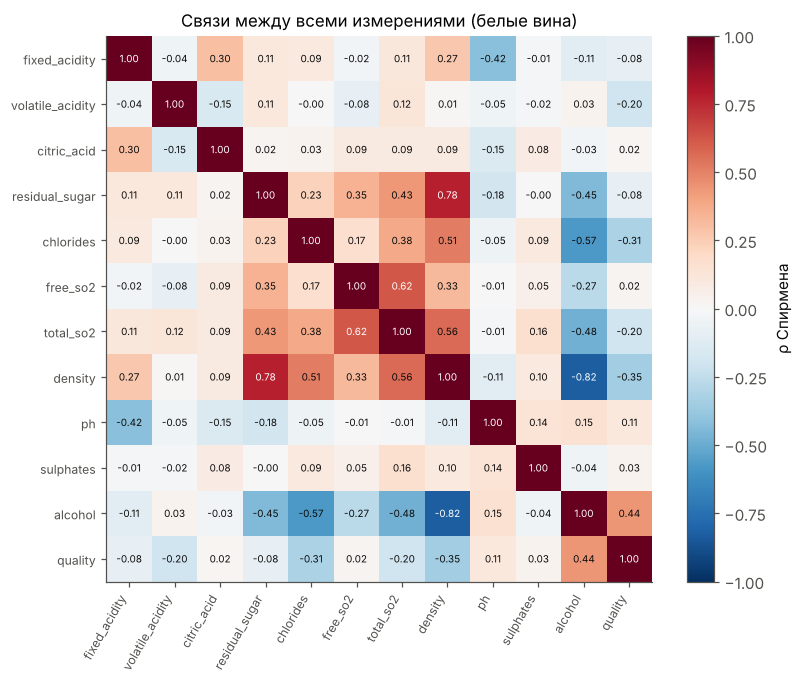

In [4]:
plots.corr_heatmap(white.corr(method="spearman"), "dataset_corr.png");

**Результаты:**

- Пропусков нет. Полных дублей строк 937 из 4898 (19 %). Совокупность взята как есть; в EDA каждой величины есть столбец «без дублей» для сравнения (средние отличаются меньше чем на 0.08).
- Шаг записи: pH 0.01; кислотность 0.1 (5 значений с шагом 0.05); спирт 0.1, кроме 69 значений вида 11.9333 или 12.8933.
- Критерий серий по порядку строк: z от −11.8 до −16.3 (p < 10⁻³⁰), автокорреляция соседних строк 0.19–0.27. H0 «порядок строк случаен» отвергается. Все выборки в работе берутся случайным отбором.
- Карта ρ Спирмена: наибольшие по модулю связи: плотность и спирт −0.82, плотность и остаточный сахар +0.78. У pH наибольшая по модулю связь с фиксированной кислотностью (−0.42).

<a id="rv01"></a>
## Random Variable 01 (pH)

<a id="rv01-desc"></a>
### Description (природа события)


**Величина.** pH = −lg a(H⁺), ед. pH, измерение pH-метром, записано с шагом 0.01.

**Событие.** Из совокупности 4898 белых вин случайно выбирается один образец, у него измерен pH.

**Что посчитано для проверки стохастической природы.** Прогноз pH по остальным 10 измерениям двумя способами на 5-кратной кросс-валидации: линейная регрессия и нелинейный прогноз по k ближайшим соседям. Для каждого: R² и СКО остатка, их сравнение с шагом записи. Плюс поиск вин с полностью совпадающими остальными измерениями и разным pH.

**TODO Сандра: природа события своими словами.** _Вопросы: от чего в реальности зависит pH вина? можно ли его посчитать по формуле, и каких данных для этого нет в датасете? что из расчёта ниже (R², остаток против шага 0.01) говорит «за» или «против» детерминированности, и что этот расчёт НЕ доказывает?_

Линейная модель: R² на кросс-валидации 0.501, СКО остатка 0.1067 ед. pH
k ближайших соседей, k = 5: R² 0.485, СКО остатка 0.1083 ед. pH
k ближайших соседей, k = 15: R² 0.435, СКО остатка 0.1135 ед. pH
k ближайших соседей, k = 30: R² 0.390, СКО остатка 0.1179 ед. pH
Шаг записи прибора: 0.01 ед. pH; СКО самой величины: 0.1510
Групп вин с одинаковыми остальными 10 измерениями, но разным значением: 0


,nunique,min,max,count


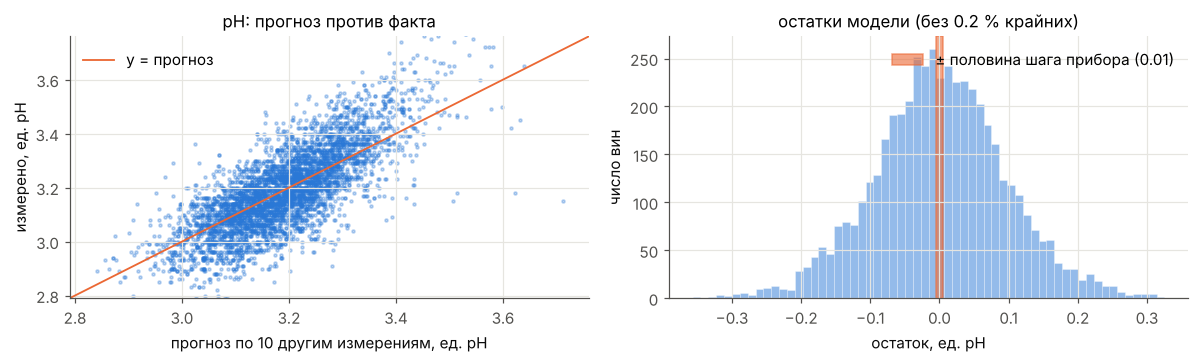

In [5]:
res_rv01 = stochastic.cv_r2_linear(X.drop(columns="ph"), X["ph"], k=5, seed=SEED)
knn_rv01 = {kk: stochastic.cv_r2_knn(X.drop(columns="ph"), X["ph"], k_neighbors=kk, k=5, seed=SEED) for kk in (5, 15, 30)}
twins_rv01 = stochastic.same_inputs_different_target(X, "ph")
print(f"Линейная модель: R² на кросс-валидации {res_rv01['r2_cv']:.3f}, СКО остатка {res_rv01['resid_std']:.4f} ед. pH")
for kk, r in knn_rv01.items():
    print(f"k ближайших соседей, k = {kk}: R² {r['r2_cv']:.3f}, СКО остатка {r['resid_std']:.4f} ед. pH")
print(f"Шаг записи прибора: 0.01 ед. pH; СКО самой величины: {X['ph'].std():.4f}")
print(f"Групп вин с одинаковыми остальными 10 измерениями, но разным значением: {len(twins_rv01)}")
plots.stochastic_panel(X["ph"].to_numpy(), res_rv01["resid"], "pH", "ед. pH", 0.01, "rv01_stochastic.png");
twins_rv01.head()

**Результаты:**

- Линейная модель по 10 другим измерениям: R² на кросс-валидации 0.50, СКО остатка 0.107 ед. pH.
- k ближайших соседей (нелинейный прогноз): R² 0.49 / 0.44 / 0.39 при k = 5 / 15 / 30, СКО остатка 0.108–0.118.
- Шаг записи 0.01, СКО самого pH 0.151.
- Групп вин с одинаковыми остальными измерениями и разным pH: 0.

<a id="rv01-eda"></a>
### EDA & Distribution

In [6]:
x_rv01 = white["ph"].to_numpy()
out_rv01 = dsc.iqr_outliers(x_rv01)
print("Выбросов по правилу 1.5·IQR:", out_rv01.sum(), f"({out_rv01.mean():.1%})")
dsc.compare_table({"белые, все": x_rv01, "белые без дублей": white.drop_duplicates()["ph"], "красные": red["ph"]}).T

Выбросов по правилу 1.5·IQR: 75 (1.5%)


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
"белые, все",4898.0,3.1883,0.0228,0.1510,0.0474,2.72,3.09,3.18,3.28,3.82,0.19,3.14,0.4576,0.5290,103.0,0.01
белые без дублей,3961.0,3.1955,0.0230,0.1515,0.0474,2.72,3.09,3.18,3.29,3.82,0.20,3.16,0.4553,0.5477,103.0,0.01
красные,1599.0,3.3111,0.0238,0.1544,0.0466,2.74,3.21,3.31,3.40,4.01,0.19,3.30,0.1935,0.8007,89.0,0.01


In [7]:
fit_rv01 = dist.fit_candidates(x_rv01)
fit_rv01

,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,2385.7600,-4765.5200,-4746.0303,0.0245,"(1.8161, 3.0412, 0.2107)"
lognorm,3,2385.7365,-4765.4731,-4745.9833,0.0246,"(0.1363, 2.0877, 1.0904)"
gamma,3,2383.8781,-4761.7563,-4742.2665,0.0250,"(26.1137, 2.4184, 0.0295)"
norm,2,2310.0684,-4616.1368,-4603.1436,0.0493,"(3.1883, 0.151)"
weibull_min,3,2250.7030,-4495.4060,-4475.9162,0.0593,"(3.0322, 2.7183, 0.5243)"


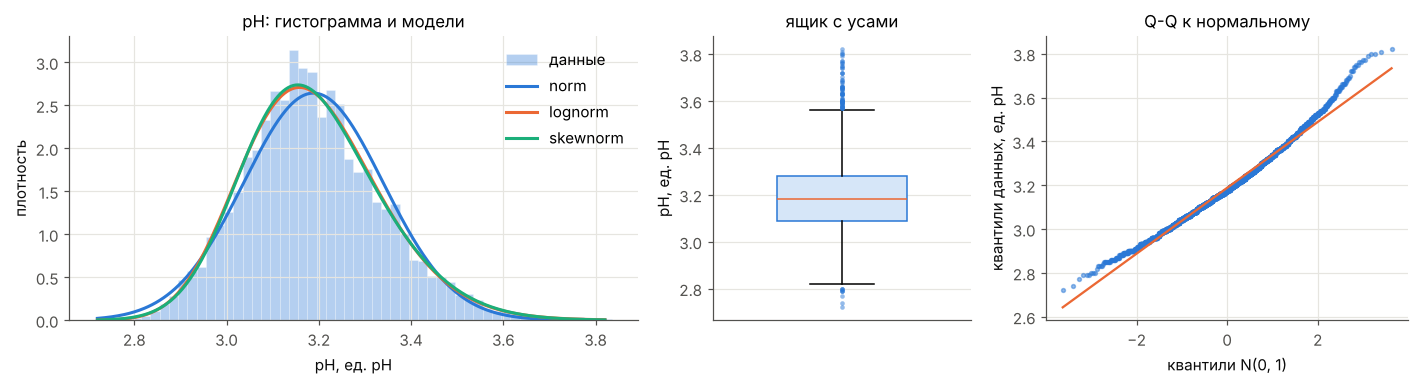

In [8]:
best_rv01 = {name: dist.fit(name, x_rv01) for name in ['norm', 'lognorm', 'skewnorm']}
plots.eda_panel(x_rv01, "pH", "ед. pH", best_rv01, "rv01_eda.png");

**Результаты:**

- N = 4898, среднее 3.188, медиана 3.18, мода 3.14, СКО 0.151, коэффициент вариации 4.7 %.
- Асимметрия +0.46, эксцесс +0.53. На Q-Q точки обоих концов лежат выше прямой.
- Выбросов по правилу 1.5·IQR 75 (1.5 %), диапазон 2.72–3.82; не удалялись.
- AIC: скошенная нормальная −4765.5, логнормальная со сдвигом −4765.5, гамма −4761.8, нормальная −4616.1. D Колмогорова 0.025 против 0.049 у нормальной.
- Красные вина: среднее 3.311, СКО 0.154.

<a id="rv01-math"></a>
#### Математическое описание распределения


**Проверяемое семейство: нормальное распределение** $N(\mu, \sigma^2)$ [2, 3]. Справочные формулы:

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\qquad F(x) = \Phi\left(\frac{x-\mu}{\sigma}\right),\quad x\in\mathbb{R}.$$

- Моменты: $E X = \mu$, $D X = \sigma^2$, асимметрия $0$, избыточный эксцесс $0$; медиана = мода = $\mu$.
- Правило трёх сигм: $P(|X-\mu|\le k\sigma) = 0.6827,\ 0.9545,\ 0.9973$ для $k = 1, 2, 3$.
- Оценки максимального правдоподобия: $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum (x_i-\bar x)^2$ (смещённая; несмещённая с $\frac{1}{n-1}$).
- Линейное преобразование нормальной величины снова нормально: $Z = (X-\mu)/\sigma \sim N(0,1)$.

**TODO Сандра: обоснование выбора распределения своими словами.** _Вопросы: почему для проверки взято именно это семейство? что видно на гистограмме и Q-Q (центр, хвосты)? какие места таблицы AIC и критерии из раздела Hypotheses подтверждают или опровергают выбор? есть ли теорема, которая объясняла бы такую форму, и выполняются ли её условия для pH?_

<a id="rv01-indep"></a>
### Independence & Estimations

**Зависимость.** Корреляции (Пирсон, Спирмен, Кендалл), хи-квадрат на таблице сопряжённости по квартилям и перестановочный тест.

In [9]:
print("pH и фиксированная кислотность")
display(dependence.correlations(white["ph"], white["fixed_acidity"]))
chi = dependence.chi2_independence(white["ph"], white["fixed_acidity"], bins=4)
perm = dependence.permutation_spearman(white["ph"], white["fixed_acidity"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

pH и фиксированная кислотность


,coef,p
method,,
pearson,-0.4259,4.8420e-215
spearman,-0.4183,7.9855e-207
kendall,-0.2948,5.2617e-199


χ² = 792.0, df = 9, p = 1.11e-164, V Крамера = 0.232
перестановочный тест: ρ = -0.418, p = 0.0005, |ρ| при H0 не больше 0.061


fixed_acidity,0,1,2,3
ph,,,,
0,123,296,332,563
1,220,395,277,354
2,385,353,237,181
3,567,296,213,106


In [10]:
print("pH и спирт")
display(dependence.correlations(white["ph"], white["alcohol"]))
chi = dependence.chi2_independence(white["ph"], white["alcohol"], bins=4)
perm = dependence.permutation_spearman(white["ph"], white["alcohol"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

pH и спирт


,coef,p
method,,
pearson,0.1214,1.4901e-17
spearman,0.1489,1.1419e-25
kendall,0.1026,5.8500e-26


χ² = 236.1, df = 9, p = 8.37e-46, V Крамера = 0.127
перестановочный тест: ρ = 0.149, p = 0.0005, |ρ| при H0 не больше 0.049


alcohol,0,1,2,3
ph,,,,
0,535,191,311,277
1,394,336,261,255
2,321,255,291,289
3,186,355,327,314


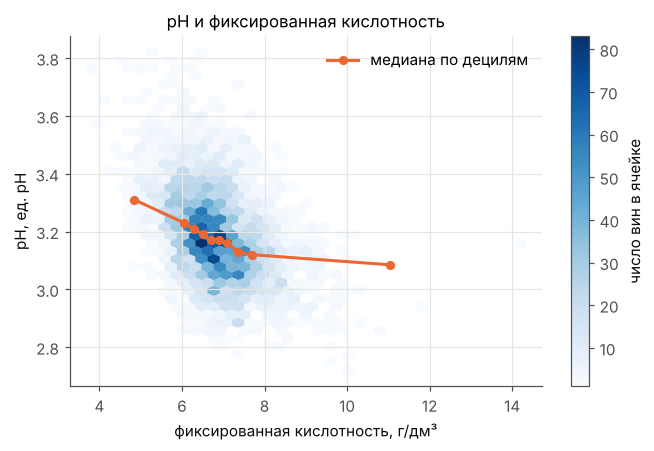

In [11]:
plots.scatter_dependence(white.fixed_acidity.to_numpy(), white.ph.to_numpy(),
                         "фиксированная кислотность, г/дм³", "pH, ед. pH",
                         "pH и фиксированная кислотность", "rv01_rv02_dependence.png");

**Результаты:**

- **pH и фиксированная кислотность:** Пирсон −0.43, Спирмен −0.42, Кендалл −0.29, все p < 10⁻¹⁹⁸. χ² на таблице 4×4 = 792 при df = 9, p ≈ 10⁻¹⁶⁴, V Крамера 0.23. Перестановочный тест: ни одна из 2000 перестановок не дала |ρ| больше 0.061 (наблюдаемое 0.418), p = 1/2001. H0 о независимости отвергается всеми тремя способами.
- Таблица сопряжённости: среди вин нижнего квартиля кислотности 567 из верхнего квартиля pH и 123 из нижнего.
- **pH и спирт:** ρ = +0.15, χ² = 236 при df = 9, p ≈ 10⁻⁴⁶, V Крамера 0.13. H0 о независимости отвергается.

**Состоятельность оценок.** Из совокупности берём выборки объёма n с возвращением (1000 повторов на каждое n) и смотрим, как оценка приближается к значению параметра в совокупности.

,оценка,n,theta,bias,sd_est,p_far,eps
0,mean,10,3.1883,-1.1986e-03,0.0472,0.753,0.0151
1,mean,30,3.1883,-1.7697e-04,0.0269,0.589,0.0151
2,mean,100,3.1883,2.6626e-04,0.0148,0.316,0.0151
3,mean,300,3.1883,9.7894e-05,0.0087,0.074,0.0151
4,mean,1000,3.1883,-1.5005e-04,0.0047,0.002,0.0151
5,mean,3000,3.1883,1.7322e-04,0.0027,0.000,0.0151
0,var,10,0.0228,1.3811e-04,0.0117,0.837,0.0023
1,var,30,0.0228,1.2134e-04,0.0067,0.726,0.0023
2,var,100,0.0228,-6.5264e-05,0.0037,0.539,0.0023
3,var,300,0.0228,4.5272e-05,0.0021,0.277,0.0023


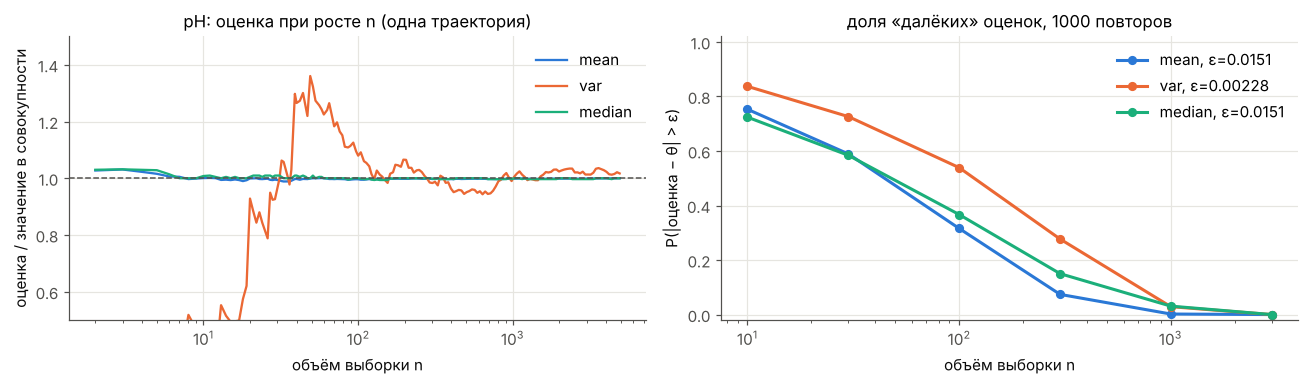

In [12]:
ns = [10, 30, 100, 300, 1000, 3000]
curves_rv01 = {e: estimation.consistency_curve(x_rv01, e, ns, reps=1000, seed=SEED) for e in ["mean", "var", "median"]}
running_rv01 = {e: estimation.running_estimate(x_rv01, e, n_max=4898, seed=SEED) for e in ["mean", "var", "median"]}
plots.consistency_panel(curves_rv01, running_rv01, "pH", "rv01_consistency.png")
pd.concat(curves_rv01, names=["оценка"]).reset_index(level=0)[["оценка", "n", "theta", "bias", "sd_est", "p_far", "eps"]]

**Результаты:**

- ε = 0.1·σ для среднего и медианы (0.0151), ε = 0.1·σ² для дисперсии.
- Доля оценок дальше ε от значения в совокупности при n = 10 → 3000: среднее 0.75 → 0.00, медиана 0.72 → 0.00, несмещённая дисперсия 0.84 → 0.00.
- СКО оценки среднего: 0.047 при n = 10, 0.0027 при n = 3000 (σ/√3000 = 0.0028).
- Смещение среднего и дисперсии в пределах ±0.0002; смещение медианы около −0.003 при всех n.

<a id="rv01-norm"></a>
### Normalization

после z: среднее -1.20e-15, СКО 1.000
доля |z| ≤ 1, 2, 3: [np.float64(0.694), np.float64(0.9573), np.float64(0.9935)] у N(0,1): [0.6827, 0.9545, 0.9973]


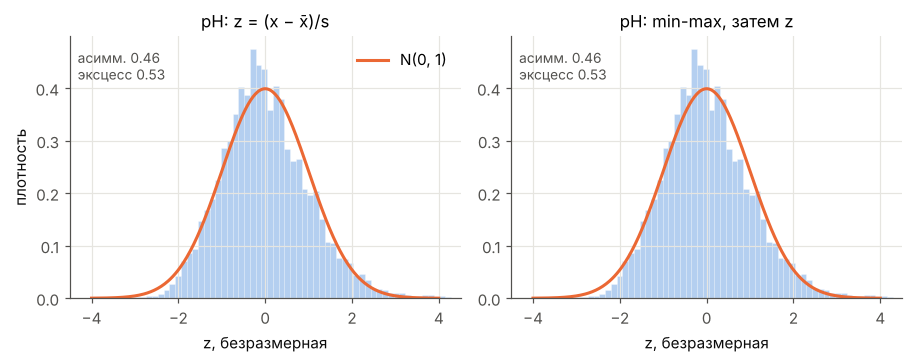

In [13]:
z_ph = normalize.zscore(x_rv01)
pairs = {"pH: z = (x − x̄)/s": z_ph, "pH: min-max, затем z": normalize.zscore(normalize.minmax(x_rv01))}
plots.normalization_panel(pairs, "rv01_normalization.png")
print(f"после z: среднее {z_ph.mean():.2e}, СКО {z_ph.std(ddof=1):.3f}")
print("доля |z| ≤ 1, 2, 3:", [round(np.mean(np.abs(z_ph) <= k), 4) for k in (1, 2, 3)], "у N(0,1): [0.6827, 0.9545, 0.9973]")

**Результаты:**

- После z-преобразования: среднее 0 (до 10⁻¹⁵), СКО 1.000, асимметрия и эксцесс те же (0.46 и 0.53). Это стандартизация.
- Доли |z| ≤ 1, 2, 3: 0.694, 0.957, 0.9935; у N(0, 1): 0.683, 0.954, 0.9973.
- Min-max, затем z: та же гистограмма, что после z.

<a id="rv01-sample"></a>
### Sample vs Population

Одна выборка n = 300 (около 6 % совокупности) двумя способами, затем повторный эксперимент для разных n.

КС выборка против совокупности: с возвращением p = 0.874, без возвращения p = 0.938
Повторов элементов в выборке с возвращением: 11


,n,mean,std,median,q25,q75,skew,kurt,ДИ 95% для среднего
совокупность,4898.0,3.1883,0.1510,3.180,3.09,3.28,0.4576,0.5290,
с возвращением,300.0,3.1801,0.1497,3.175,3.08,3.28,0.2886,0.1591,"[3.1631, 3.1971]"
без возвращения,300.0,3.1944,0.1564,3.180,3.08,3.29,0.4234,0.7626,"[3.1772, 3.2116]"


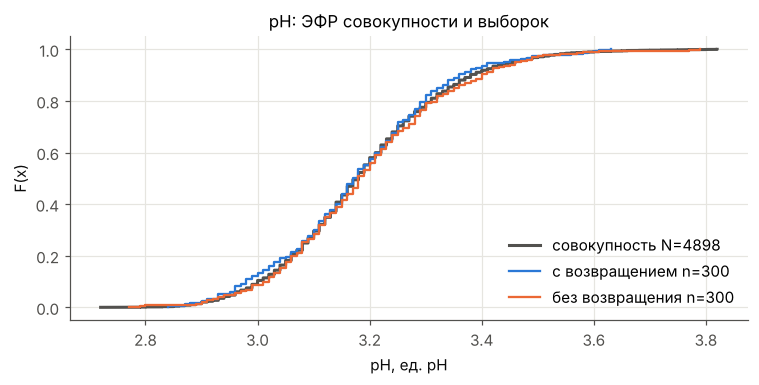

In [14]:
n = 300
s_with_rv01 = sampling.draw(x_rv01, n, replace=True, seed=SEED)
s_without_rv01 = sampling.draw(x_rv01, n, replace=False, seed=SEED)
tab = dsc.compare_table({"совокупность": x_rv01, "с возвращением": s_with_rv01, "без возвращения": s_without_rv01}).T
tab["ДИ 95% для среднего"] = ["", np.round(sampling.ci_mean(s_with_rv01), 4), np.round(sampling.ci_mean(s_without_rv01, N=len(x_rv01)), 4)]
ks_w, ks_wo = stats.ks_2samp(s_with_rv01, x_rv01), stats.ks_2samp(s_without_rv01, x_rv01)
print(f"КС выборка против совокупности: с возвращением p = {ks_w.pvalue:.3f}, без возвращения p = {ks_wo.pvalue:.3f}")
print("Повторов элементов в выборке с возвращением:", n - len(np.unique(sampling.draw(np.arange(len(x_rv01)), n, True, SEED))))
plots.sampling_panel(x_rv01, s_with_rv01, s_without_rv01, "pH", "ед. pH", "rv01_sampling.png")
tab[["n", "mean", "std", "median", "q25", "q75", "skew", "kurt", "ДИ 95% для среднего"]]

,n,n/N,se_with_emp,se_with_theory,se_without_emp,se_without_theory
0,100,0.0204,0.0148,0.0151,0.0146,0.0149
1,1000,0.2042,0.0047,0.0048,0.0043,0.0043
2,2500,0.5104,0.0030,0.0030,0.0021,0.0021
3,4000,0.8167,0.0024,0.0024,0.0010,0.0010


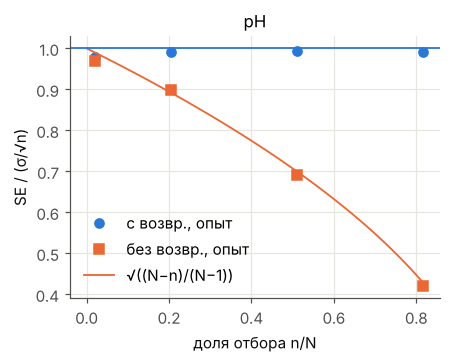

In [15]:
se_rv01 = sampling.se_mean_experiment(x_rv01, [100, 1000, 2500, 4000], reps=2000, seed=SEED)
plots.se_panel({"pH": se_rv01}, "rv01_se.png")
se_rv01

**Результаты:**

- Выборка n = 300: среднее 3.180 (с возвращением) и 3.194 (без) при 3.188 в совокупности. 95 % ДИ: [3.163; 3.197] и [3.177; 3.212], оба накрывают 3.188.
- КС «выборка против совокупности»: p = 0.87 и 0.94. (Выборка является частью совокупности, поэтому этот критерий здесь только иллюстрация.)
- В выборке с возвращением 11 вин попали дважды (ожидаемое число около n²/2N ≈ 9).
- 2000 повторов: с возвращением СКО среднего совпадает с σ/√n при всех n. Без возвращения совпадает с σ/√n·√((N−n)/(N−1)): при n = 4000 0.0010 против 0.0024; при n = 100 0.0146 против 0.0148.

<a id="rv01-hyp"></a>
### Hypotheses

Уровень значимости α = 0.05 для каждой проверки; поправка на множественность в [Lab resume](#resume).

,данные,test,H0,p,решение
0,все 4898,D'Agostino K²,X ~ нормальное,1.0892e-42,отвергаем H0
1,все 4898,"χ² Пирсона, 19 интервалов, df 16",X ~ нормальное,1.1098e-14,отвергаем H0
2,все 4898,"КС, параметрический бутстреп с округлением",X ~ нормальное,3.3223e-03,отвергаем H0
3,выборка 200,D'Agostino K²,X ~ нормальное,1.3908e-01,нет оснований отвергнуть H0
4,выборка 200,Shapiro–Wilk,X ~ нормальное,7.0652e-02,нет оснований отвергнуть H0
5,все 4898,"χ² Пирсона, 19 интервалов, df 15",X ~ логнормальное со сдвигом,5.5549e-02,нет оснований отвергнуть H0


{'test': 'Welch t', 'H0': 'E[A] = E[B]', 'stat': -27.775496831893292, 'p': 2.3422645384856133e-149, 'decision': 'отвергаем H0', 'diff': -0.12284655630267016}


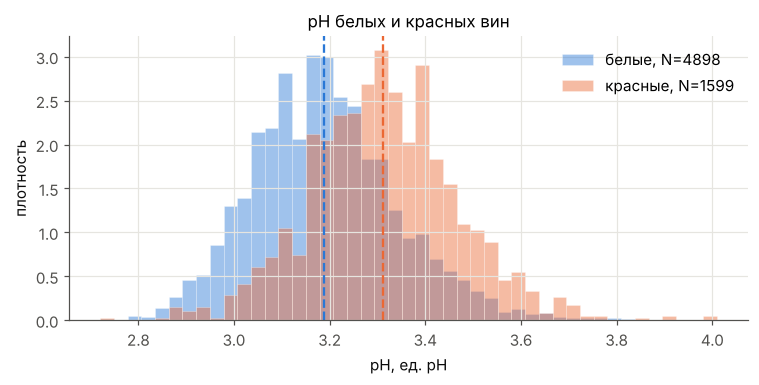

In [16]:
# H1: pH белых вин распределён нормально; H1b: pH ~ логнормальное со сдвигом
sub = sampling.draw(x_rv01, 200, replace=False, seed=SEED)
chi_norm_rv01 = dist.chi2_gof(x_rv01, "norm")          # параметры по интервалам, границы на полушагах 0.005
chi_lognorm_rv01 = dist.chi2_gof(x_rv01, "lognorm")
ks_rv01 = dist.ks_bootstrap(x_rv01, "norm", B=300, seed=SEED)   # бутстреп-выборки округляются до 0.01
rows = [
    hyp.normality_dagostino(x_rv01) | {"данные": "все 4898"},
    chi_norm_rv01 | {"test": f"χ² Пирсона, {chi_norm_rv01['bins']} интервалов, df {chi_norm_rv01['dof']}", "H0": "X ~ нормальное", "данные": "все 4898"},
    ks_rv01 | {"test": "КС, параметрический бутстреп с округлением", "H0": "X ~ нормальное", "данные": "все 4898"},
    hyp.normality_dagostino(sub) | {"данные": "выборка 200"},
    hyp.shapiro(sub) | {"данные": "выборка 200"},
    chi_lognorm_rv01 | {"test": f"χ² Пирсона, {chi_lognorm_rv01['bins']} интервалов, df {chi_lognorm_rv01['dof']}", "H0": "X ~ логнормальное со сдвигом", "данные": "все 4898"},
]
h_rv01 = pd.DataFrame(rows)[["данные", "test", "H0", "p"]]
h_rv01["решение"] = np.where(h_rv01.p < 0.05, "отвергаем H0", "нет оснований отвергнуть H0")
display(h_rv01)

# H2: средний pH белых и красных вин одинаков
h2 = hyp.welch_t(white.ph, red.ph)
print(h2)
plots.two_groups(white.ph.to_numpy(), red.ph.to_numpy(), "белые, N=4898", "красные, N=1599",
                 "pH, ед. pH", "pH белых и красных вин", "rv01_white_vs_red.png");

In [17]:
# Калибровка критериев: данные, которые ТОЧНО нормальны, с теми же μ, σ, N и округлением до 0.01.
# Правильный критерий отвергает H0 примерно в 5 % таких случаев.
calib_rv01 = dist.calibration("norm", (x_rv01.mean(), x_rv01.std()), n=len(x_rv01), step=0.01, sims=200, B=99, seed=SEED)
pd.Series(calib_rv01)

chi2_reject_rate      0.035
chi2_sims           200.000
ks_reject_rate        0.020
ks_sims              50.000
dtype: float64

**Результаты:**

- **H1 (pH нормален), все 4898:** K² p ≈ 10⁻⁴²; χ² (19 интервалов, df 16) p ≈ 10⁻¹⁴; КС с параметрическим бутстрепом p = 0.003 (ни одна из 300 бутстреп-выборок не дала D больше наблюдаемого). H0 отвергается.
- **H1 на случайной выборке 200:** K² p = 0.14, Шапиро–Уилк p = 0.07. H0 не отвергается.
- **H1b (pH логнормален со сдвигом):** χ² (19 интервалов, df 15) p = 0.056. H0 не отвергается. Семейство выбрано после просмотра таблицы AIC.
- **H2 (средний pH белых = красных):** t Уэлча = −27.8, p ≈ 10⁻¹⁴⁹, разница −0.123. H0 отвергается.
- **Калибровка критериев** на 200 симулированных нормальных наборах с теми же μ, σ, N и округлением 0.01: χ² отверг H0 в 3.5 % случаев, КС-бутстреп в 2 % (50 наборов). Номинал 5 %.

<a id="rv01-resume"></a>
### Resume

**TODO Сандра: вывод своими словами.**

_Вопросы:_
- _Какой вывод о случайности pH следует из R² линейной модели и k соседей, и где граница этого вывода?_
- _Что видно на гистограмме и Q-Q? Как это согласуется с асимметрией и эксцессом?_
- _Почему решения критериев нормальности на 4898 винах и на выборке 200 разные? Что это значит для практики?_
- _Что показал χ² для логнормального семейства? Можно ли честно выбирать семейство после того, как посмотрели на AIC?_
- _Что дала выборка 300: совпали ли статистики с совокупностью? Когда нужна поправка на конечность?_
- _Чем различаются pH белых и красных вин? Как это объяснить химически (поискать в источниках)?_

<a id="rv02"></a>
## Random Variable 02 (фиксированная кислотность)

<a id="rv02-desc"></a>
### Description (природа события)


**Величина.** Фиксированная (нелетучая) кислотность, г/дм³ в пересчёте на винную кислоту, определяется титрованием, записана с шагом 0.1. Как и pH, характеризует кислотность вина, поэтому для пары RV01–RV02 проверяется зависимость.

**Событие.** Случайно выбирается образец белого вина, у него измерена кислотность.

**Что посчитано.** Те же проверки, что для pH: линейный прогноз и k ближайших соседей по 10 другим измерениям, поиск «двойников».

**TODO Сандра: природа события своими словами.** _Вопросы: от чего зависит содержание кислот в вине? почему pH и кислотность одной природы, но не одно и то же? что показывают «двойники» ниже?_

Линейная модель: R² на кросс-валидации 0.584, СКО остатка 0.5446 г/дм³
k ближайших соседей, k = 5: R² 0.472, СКО остатка 0.6135 г/дм³
k ближайших соседей, k = 15: R² 0.433, СКО остатка 0.6355 г/дм³
k ближайших соседей, k = 30: R² 0.401, СКО остатка 0.6533 г/дм³
Шаг записи прибора: 0.1 г/дм³; СКО самой величины: 0.8439
Групп вин с одинаковыми остальными 10 измерениями, но разным значением: 18


,nunique,min,max,count
0,2,6.4,6.5,2
1,2,5.4,5.6,3
2,2,5.5,5.6,2
3,2,5.4,5.6,2
4,2,4.9,5.0,2


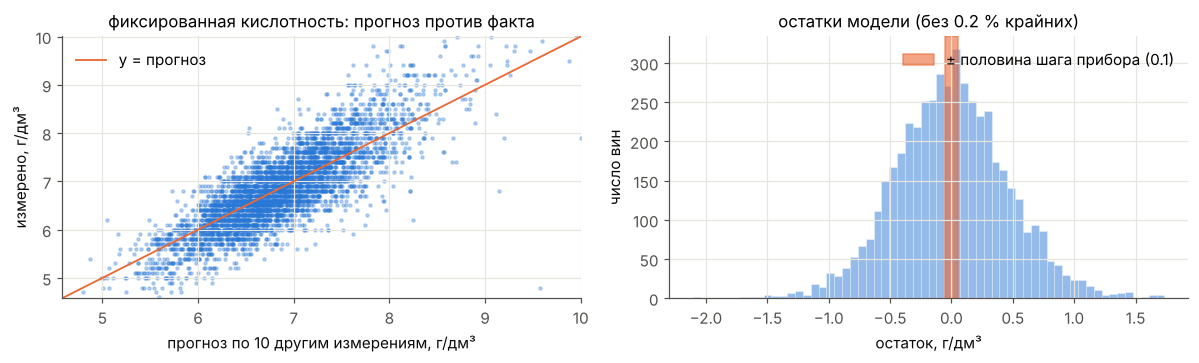

In [18]:
res_rv02 = stochastic.cv_r2_linear(X.drop(columns="fixed_acidity"), X["fixed_acidity"], k=5, seed=SEED)
knn_rv02 = {kk: stochastic.cv_r2_knn(X.drop(columns="fixed_acidity"), X["fixed_acidity"], k_neighbors=kk, k=5, seed=SEED) for kk in (5, 15, 30)}
twins_rv02 = stochastic.same_inputs_different_target(X, "fixed_acidity")
print(f"Линейная модель: R² на кросс-валидации {res_rv02['r2_cv']:.3f}, СКО остатка {res_rv02['resid_std']:.4f} г/дм³")
for kk, r in knn_rv02.items():
    print(f"k ближайших соседей, k = {kk}: R² {r['r2_cv']:.3f}, СКО остатка {r['resid_std']:.4f} г/дм³")
print(f"Шаг записи прибора: 0.1 г/дм³; СКО самой величины: {X['fixed_acidity'].std():.4f}")
print(f"Групп вин с одинаковыми остальными 10 измерениями, но разным значением: {len(twins_rv02)}")
plots.stochastic_panel(X["fixed_acidity"].to_numpy(), res_rv02["resid"], "фиксированная кислотность", "г/дм³", 0.1, "rv02_stochastic.png");
twins_rv02.head()

**Результаты:**

- Линейная модель: R² 0.58, СКО остатка 0.54 г/дм³. k ближайших соседей: R² 0.47 / 0.43 / 0.40 при k = 5 / 15 / 30, СКО остатка 0.61–0.65.
- Шаг записи 0.1 г/дм³, СКО самой величины 0.84.
- 18 групп вин с одинаковыми остальными 10 измерениями и разной кислотностью; разница в группах от 0.1 до 0.3 г/дм³ (например, 5.4 и 5.6), в одной группе 6.8 г/дм³.

<a id="rv02-eda"></a>
### EDA & Distribution

In [19]:
x_rv02 = white["fixed_acidity"].to_numpy()
out_rv02 = dsc.iqr_outliers(x_rv02)
print("Выбросов по правилу 1.5·IQR:", out_rv02.sum(), f"({out_rv02.mean():.1%})")
dsc.compare_table({"белые, все": x_rv02, "белые без дублей": white.drop_duplicates()["fixed_acidity"], "красные": red["fixed_acidity"]}).T

Выбросов по правилу 1.5·IQR: 119 (2.4%)


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
"белые, все",4898.0,6.8548,0.7121,0.8439,0.1231,3.8,6.3,6.8,7.3,14.2,1.0,6.8,0.6476,2.1687,68.0,0.05
белые без дублей,3961.0,6.8393,0.7514,0.8669,0.1267,3.8,6.3,6.8,7.3,14.2,1.0,6.8,0.6958,2.2487,68.0,0.05
красные,1599.0,8.3196,3.0314,1.7411,0.2093,4.6,7.1,7.9,9.2,15.9,2.1,7.2,0.9818,1.1249,96.0,0.10


In [20]:
fit_rv02 = dist.fit_candidates(x_rv02)
fit_rv02

,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,-6017.3683,12040.7366,12060.2264,0.0419,"(1.8102, 6.0421, 1.1715)"
lognorm,3,-6019.1276,12044.2553,12063.7450,0.0439,"(0.1296, 0.4198, 6.381)"
gamma,3,-6027.0201,12060.0402,12079.5299,0.0435,"(32.4957, 2.0843, 0.1468)"
norm,2,-6117.9817,12239.9633,12252.9565,0.0662,"(6.8548, 0.8438)"
weibull_min,3,-6265.6653,12537.3306,12556.8203,0.0724,"(3.7074, 3.7835, 3.3833)"


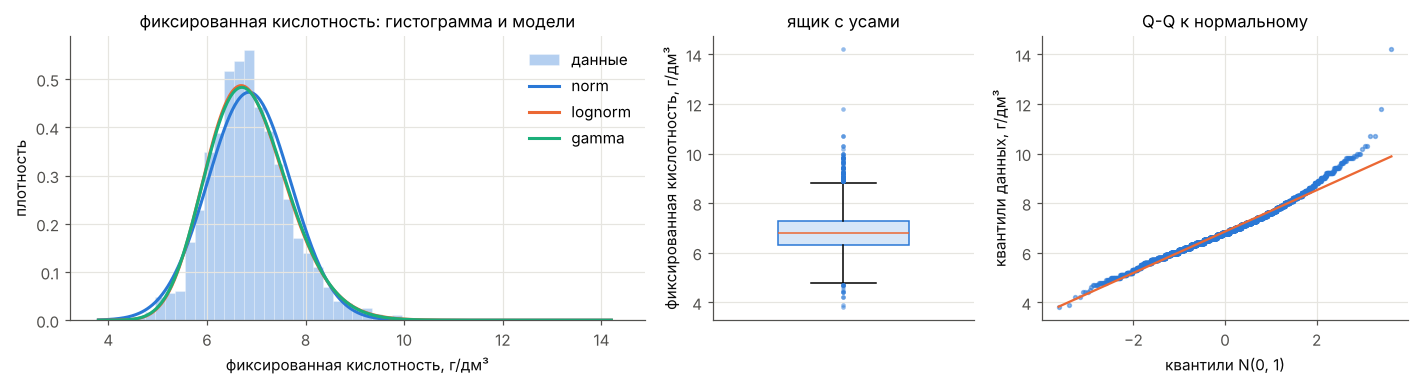

In [21]:
best_rv02 = {name: dist.fit(name, x_rv02) for name in ['norm', 'lognorm', 'gamma']}
plots.eda_panel(x_rv02, "фиксированная кислотность", "г/дм³", best_rv02, "rv02_eda.png");

**Результаты:**

- Среднее 6.85, медиана 6.8, мода 6.8 г/дм³, СКО 0.84, КВ 12 %.
- Асимметрия +0.65, эксцесс +2.17. Выбросов 119 (2.4 %), максимум 14.2 при Q3 = 7.3.
- AIC: скошенная нормальная 12040.7, логнормальная со сдвигом 12044.3, гамма 12060.0, нормальная 12240.0. Оценка сдвига логнормальной 0.42 г/дм³.
- Красные вина: 8.32 ± 1.74 г/дм³.

<a id="rv02-math"></a>
#### Математическое описание распределения


**Проверяемое семейство: логнормальное распределение** [2, 4]. Справочные формулы. $X$ логнормальна, если $\ln X \sim N(\mu, \sigma^2)$. Трёхпараметрическая форма со сдвигом $\theta$ (в scipy: `s` = σ, `loc` = θ, `scale` = $e^{\mu}$):

$$f(x) = \frac{1}{(x-\theta)\,\sigma\sqrt{2\pi}}\exp\left(-\frac{(\ln(x-\theta)-\mu)^2}{2\sigma^2}\right),\quad x > \theta.$$

- Моменты (при θ = 0): $E X = e^{\mu+\sigma^2/2}$, $D X = (e^{\sigma^2}-1)\,e^{2\mu+\sigma^2}$, медиана $e^{\mu}$, мода $e^{\mu-\sigma^2}$, т. е. мода < медиана < среднее.
- Асимметрия $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1} > 0$.
- Нормализация: $Z = (\ln(X-\theta) - \mu)/\sigma \sim N(0, 1)$.

В разделе Hypotheses проверяются оба варианта: без сдвига (H3, через нормальность ln X) и со сдвигом (H3b, χ²).

**TODO Сандра: обоснование выбора распределения своими словами.** _Вопросы: почему для проверки взято это семейство? какие свойства величины (область значений, форма гистограммы) с ним согласуются? что изменилось после логарифмирования в разделе Normalization? что показали H3 и H3b и как это совместить с таблицей AIC?_

<a id="rv02-indep"></a>
### Independence & Estimations

**Зависимость.** Корреляции (Пирсон, Спирмен, Кендалл), хи-квадрат на таблице сопряжённости по квартилям и перестановочный тест.

In [22]:
print("фиксированная кислотность и pH")
display(dependence.correlations(white["fixed_acidity"], white["ph"]))
chi = dependence.chi2_independence(white["fixed_acidity"], white["ph"], bins=4)
perm = dependence.permutation_spearman(white["fixed_acidity"], white["ph"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

фиксированная кислотность и pH


,coef,p
method,,
pearson,-0.4259,4.8420e-215
spearman,-0.4183,7.9855e-207
kendall,-0.2948,5.2617e-199


χ² = 792.0, df = 9, p = 1.11e-164, V Крамера = 0.232
перестановочный тест: ρ = -0.418, p = 0.0005, |ρ| при H0 не больше 0.051


ph,0,1,2,3
fixed_acidity,,,,
0,123,220,385,567
1,296,395,353,296
2,332,277,237,213
3,563,354,181,106


In [23]:
print("фиксированная кислотность и спирт")
display(dependence.correlations(white["fixed_acidity"], white["alcohol"]))
chi = dependence.chi2_independence(white["fixed_acidity"], white["alcohol"], bins=4)
perm = dependence.permutation_spearman(white["fixed_acidity"], white["alcohol"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

фиксированная кислотность и спирт


,coef,p
method,,
pearson,-0.1209,2.0854e-17
spearman,-0.1068,6.5824e-14
kendall,-0.0732,8.7284e-14


χ² = 94.6, df = 9, p = 1.98e-16, V Крамера = 0.080
перестановочный тест: ρ = -0.107, p = 0.0005, |ρ| при H0 не больше 0.052


alcohol,0,1,2,3
fixed_acidity,,,,
0,300,267,333,395
1,444,322,284,290
2,347,220,265,227
3,345,328,308,223


**Результаты:**

- **С pH:** те же числа, что в RV01 (ρ = −0.42, χ² = 792, V = 0.23).
- **Со спиртом:** ρ = −0.11, χ² = 94.6 при df = 9, p ≈ 10⁻¹⁶, V Крамера 0.08. H0 о независимости отвергается.

**Состоятельность оценок.** Из совокупности берём выборки объёма n с возвращением (1000 повторов на каждое n) и смотрим, как оценка приближается к значению параметра в совокупности.

,оценка,n,theta,bias,sd_est,p_far,eps
0,mean,10,6.8548,-6.8177e-03,0.2624,0.752,0.0844
1,mean,30,6.8548,9.2907e-03,0.1498,0.566,0.0844
2,mean,100,6.8548,-2.2697e-03,0.0832,0.319,0.0844
3,mean,300,6.8548,-3.7334e-04,0.0476,0.075,0.0844
4,mean,1000,6.8548,1.2705e-03,0.0274,0.001,0.0844
5,mean,3000,6.8548,6.1132e-05,0.0153,0.000,0.0844
0,var,10,0.7120,3.2769e-02,0.4867,0.841,0.0712
1,var,30,0.7120,5.5024e-03,0.2657,0.766,0.0712
2,var,100,0.7120,-6.0822e-03,0.1304,0.560,0.0712
3,var,300,0.7120,2.0691e-03,0.0873,0.400,0.0712


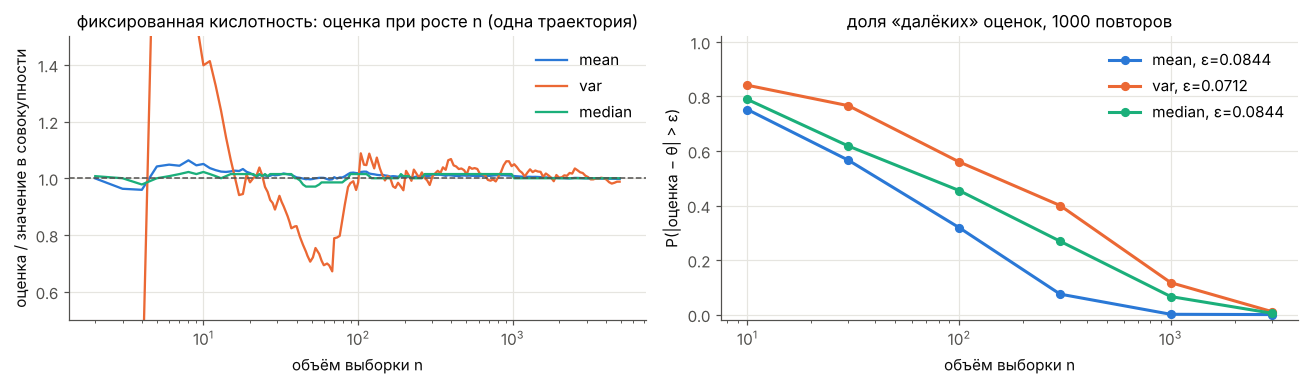

In [24]:
ns = [10, 30, 100, 300, 1000, 3000]
curves_rv02 = {e: estimation.consistency_curve(x_rv02, e, ns, reps=1000, seed=SEED) for e in ["mean", "var", "median"]}
running_rv02 = {e: estimation.running_estimate(x_rv02, e, n_max=4898, seed=SEED) for e in ["mean", "var", "median"]}
plots.consistency_panel(curves_rv02, running_rv02, "фиксированная кислотность", "rv02_consistency.png")
pd.concat(curves_rv02, names=["оценка"]).reset_index(level=0)[["оценка", "n", "theta", "bias", "sd_est", "p_far", "eps"]]

**Результаты:**

- ε = 0.084 г/дм³ для среднего и медианы, 0.071 для дисперсии.
- Доля «далёких» оценок при n = 10 → 3000: среднее 0.75 → 0.00, медиана 0.79 → 0.005, дисперсия 0.84 → 0.011.
- Из трёх оценок дисперсия при n = 1000 и 3000 даёт наибольшую долю «далёких» (0.117 и 0.011).

<a id="rv02-norm"></a>
### Normalization

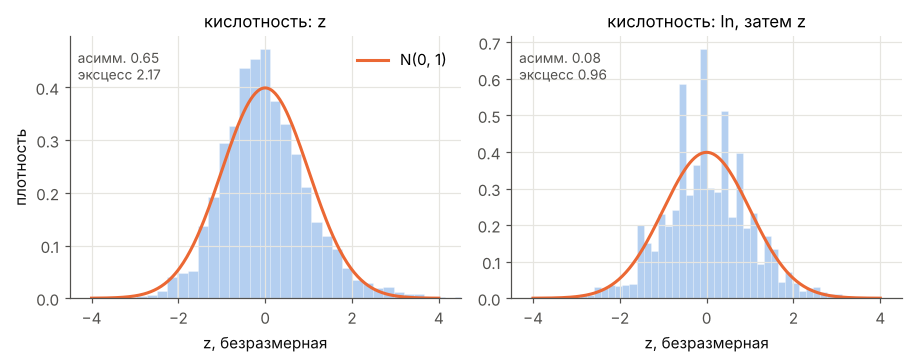

In [25]:
z_fa = normalize.zscore(x_rv02)
lz_fa = normalize.log_z(x_rv02)
plots.normalization_panel({"кислотность: z": z_fa, "кислотность: ln, затем z": lz_fa}, "rv02_normalization.png");

**Результаты:**

- После z: асимметрия 0.65, эксцесс 2.17 (не изменились). После ln и z: асимметрия 0.08, эксцесс 0.96.

<a id="rv02-sample"></a>
### Sample vs Population

Одна выборка n = 300 (около 6 % совокупности) двумя способами, затем повторный эксперимент для разных n.

КС выборка против совокупности: с возвращением p = 0.354, без возвращения p = 1.000
Повторов элементов в выборке с возвращением: 11


,n,mean,std,median,q25,q75,skew,kurt,ДИ 95% для среднего
совокупность,4898.0,6.8548,0.8439,6.8,6.3,7.3,0.6476,2.1687,
с возвращением,300.0,6.9390,0.8475,6.9,6.4,7.4,0.4428,0.7265,"[6.8427, 7.0353]"
без возвращения,300.0,6.8617,0.8528,6.8,6.3,7.4,0.4155,0.6760,"[6.7678, 6.9556]"


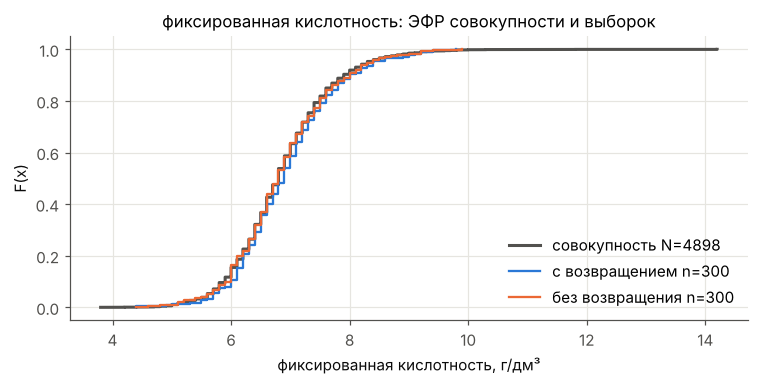

In [26]:
n = 300
s_with_rv02 = sampling.draw(x_rv02, n, replace=True, seed=SEED)
s_without_rv02 = sampling.draw(x_rv02, n, replace=False, seed=SEED)
tab = dsc.compare_table({"совокупность": x_rv02, "с возвращением": s_with_rv02, "без возвращения": s_without_rv02}).T
tab["ДИ 95% для среднего"] = ["", np.round(sampling.ci_mean(s_with_rv02), 4), np.round(sampling.ci_mean(s_without_rv02, N=len(x_rv02)), 4)]
ks_w, ks_wo = stats.ks_2samp(s_with_rv02, x_rv02), stats.ks_2samp(s_without_rv02, x_rv02)
print(f"КС выборка против совокупности: с возвращением p = {ks_w.pvalue:.3f}, без возвращения p = {ks_wo.pvalue:.3f}")
print("Повторов элементов в выборке с возвращением:", n - len(np.unique(sampling.draw(np.arange(len(x_rv02)), n, True, SEED))))
plots.sampling_panel(x_rv02, s_with_rv02, s_without_rv02, "фиксированная кислотность", "г/дм³", "rv02_sampling.png")
tab[["n", "mean", "std", "median", "q25", "q75", "skew", "kurt", "ДИ 95% для среднего"]]

,n,n/N,se_with_emp,se_with_theory,se_without_emp,se_without_theory
0,100,0.0204,0.0843,0.0844,0.0841,0.0835
1,1000,0.2042,0.0267,0.0267,0.0239,0.0238
2,2500,0.5104,0.0166,0.0169,0.0122,0.0118
3,4000,0.8167,0.0130,0.0133,0.0058,0.0057


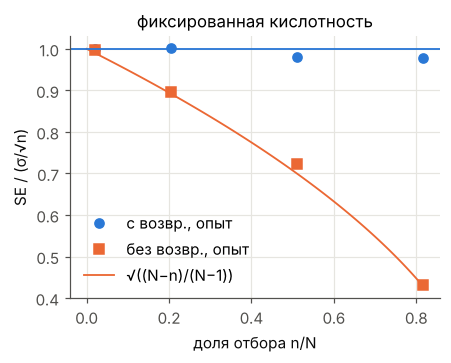

In [27]:
se_rv02 = sampling.se_mean_experiment(x_rv02, [100, 1000, 2500, 4000], reps=2000, seed=SEED)
plots.se_panel({"фиксированная кислотность": se_rv02}, "rv02_se.png")
se_rv02

**Результаты:**

- n = 300: среднее 6.94 (с возвращением) и 6.86 (без) при 6.85 в совокупности. Оба 95 % ДИ накрывают 6.85.
- Асимметрия и эксцесс в выборках 0.42–0.44 и 0.68–0.73 при 0.65 и 2.17 в совокупности.
- SE среднего без возвращения при n = 4000: 0.0058 против 0.0130 с возвращением; теория 0.0057.

<a id="rv02-hyp"></a>
### Hypotheses

Уровень значимости α = 0.05 для каждой проверки; поправка на множественность в [Lab resume](#resume).

In [28]:
# H3: ln(кислотности) распределён нормально (кислотность логнормальна без сдвига)
# H3b: кислотность ~ логнормальное со сдвигом (3 параметра)
lx = np.log(x_rv02)
sub = sampling.draw(x_rv02, 200, replace=False, seed=SEED)
chi_ln_rv02 = dist.chi2_gof(lx, "norm", step=0)        # после логарифма сетка неравномерная, step=0
chi_ln3_rv02 = dist.chi2_gof(x_rv02, "lognorm")        # шаг 0.1 определяется по данным
rows = [
    hyp.normality_dagostino(lx) | {"H0": "ln X ~ нормальное", "данные": "ln X, все 4898"},
    chi_ln_rv02 | {"test": f"χ² Пирсона, {chi_ln_rv02['bins']} интервалов", "H0": "ln X ~ нормальное", "данные": "ln X, все 4898"},
    chi_ln3_rv02 | {"test": f"χ² Пирсона, {chi_ln3_rv02['bins']} интервалов, df {chi_ln3_rv02['dof']}", "H0": "X ~ логнормальное со сдвигом", "данные": "X, все 4898"},
    hyp.normality_dagostino(np.log(sub)) | {"H0": "ln X ~ нормальное", "данные": "ln X, выборка 200"},
    hyp.normality_dagostino(x_rv02) | {"H0": "X ~ нормальное", "данные": "X, все 4898"},
]
h_rv02 = pd.DataFrame(rows)[["данные", "test", "H0", "p"]]
h_rv02["решение"] = np.where(h_rv02.p < 0.05, "отвергаем H0", "нет оснований отвергнуть H0")
h_rv02

,данные,test,H0,p,решение
0,"ln X, все 4898",D'Agostino K²,ln X ~ нормальное,1.8880e-21,отвергаем H0
1,"ln X, все 4898","χ² Пирсона, 20 интервалов",ln X ~ нормальное,1.2739e-08,отвергаем H0
2,"X, все 4898","χ² Пирсона, 17 интервалов, df 13",X ~ логнормальное со сдвигом,3.0871e-06,отвергаем H0
3,"ln X, выборка 200",D'Agostino K²,ln X ~ нормальное,4.4889e-01,нет оснований отвергнуть H0
4,"X, все 4898",D'Agostino K²,X ~ нормальное,5.1923e-118,отвергаем H0


**Результаты:**

- **H3 (ln X нормален, логнормальное без сдвига):** K² p ≈ 10⁻²¹, χ² p ≈ 10⁻⁸ на всех 4898. H0 отвергается. На выборке 200: K² p = 0.45.
- **H3b (логнормальное со сдвигом):** χ² (17 интервалов, df 13) p ≈ 3·10⁻⁶. H0 отвергается.
- Для сравнения: X нормален, K² p ≈ 10⁻¹¹⁸. Статистика K² 540 для X и 95 для ln X.

<a id="rv02-resume"></a>
### Resume

**TODO Сандра: вывод своими словами.**

_Вопросы:_
- _Что требует условие для двух величин одной природы и что показали три способа проверки для pH и кислотности?_
- _Чем отличается то, что проверяют корреляции, от того, что проверяет χ² на таблице сопряжённости?_
- _Насколько сильна связь по ρ и V Крамера? Как это выглядит на графике pH против кислотности?_
- _Что изменилось после логарифмирования? Что показали H3 и H3b?_
- _Как ведёт себя P(|оценка − θ| > ε) при росте n для каждой оценки? Какая сходится медленнее и почему, по-вашему?_

<a id="rv03"></a>
## Random Variable 03 (спирт)

<a id="rv03-desc"></a>
### Description (природа события)


**Величина.** Объёмная доля этанола, % об., записана с шагом 0.1 (69 значений не на этой сетке, см. EDA датасета).

**Событие.** Случайно выбирается образец белого вина, у него измерено содержание спирта.

**Что посчитано.** Те же проверки: линейный прогноз и k ближайших соседей по 10 другим измерениям, поиск «двойников».

**TODO Сандра: природа события своими словами.** _Вопросы: откуда берётся спирт в вине и от чего зависит его доля? это та же природа, что у pH и кислотности, или другая? какие из 10 измерений физически связаны со спиртом (посмотреть карту корреляций)? R² здесь выше, чем у pH: значит ли это, что спирт не случайная величина?_

Линейная модель: R² на кросс-валидации 0.861, СКО остатка 0.4590 % об.
k ближайших соседей, k = 5: R² 0.791, СКО остатка 0.5629 % об.
k ближайших соседей, k = 15: R² 0.772, СКО остатка 0.5880 % об.
k ближайших соседей, k = 30: R² 0.749, СКО остатка 0.6169 % об.
Шаг записи прибора: 0.1 % об.; СКО самой величины: 1.2306
Групп вин с одинаковыми остальными 10 измерениями, но разным значением: 10


,nunique,min,max,count
0,2,11.6333,11.65,2
1,2,9.7333,9.75,2
2,2,10.1333,10.15,2
3,2,11.7333,11.75,2
4,2,10.9667,11.00,4


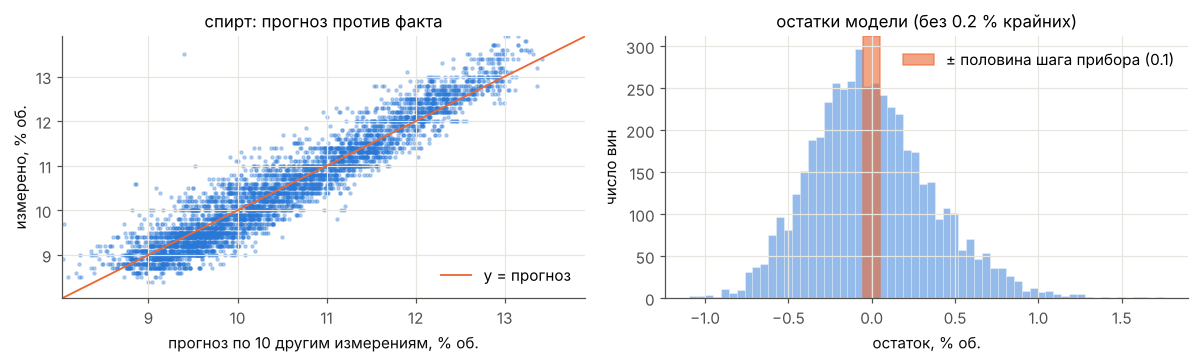

In [29]:
res_rv03 = stochastic.cv_r2_linear(X.drop(columns="alcohol"), X["alcohol"], k=5, seed=SEED)
knn_rv03 = {kk: stochastic.cv_r2_knn(X.drop(columns="alcohol"), X["alcohol"], k_neighbors=kk, k=5, seed=SEED) for kk in (5, 15, 30)}
twins_rv03 = stochastic.same_inputs_different_target(X, "alcohol")
print(f"Линейная модель: R² на кросс-валидации {res_rv03['r2_cv']:.3f}, СКО остатка {res_rv03['resid_std']:.4f} % об.")
for kk, r in knn_rv03.items():
    print(f"k ближайших соседей, k = {kk}: R² {r['r2_cv']:.3f}, СКО остатка {r['resid_std']:.4f} % об.")
print(f"Шаг записи прибора: 0.1 % об.; СКО самой величины: {X['alcohol'].std():.4f}")
print(f"Групп вин с одинаковыми остальными 10 измерениями, но разным значением: {len(twins_rv03)}")
plots.stochastic_panel(X["alcohol"].to_numpy(), res_rv03["resid"], "спирт", "% об.", 0.1, "rv03_stochastic.png");
twins_rv03.head()

**Результаты:**

- Линейная модель: R² 0.86, СКО остатка 0.46 % об. k ближайших соседей: R² 0.79 / 0.77 / 0.75 при k = 5 / 15 / 30, СКО остатка 0.56–0.62.
- Шаг записи 0.1 % об., СКО самой величины 1.23.
- 10 групп вин с одинаковыми остальными измерениями и разным спиртом, разница в группах 0.017–0.03 % об. (например, 11.633 и 11.65), то есть меньше шага записи.
- На графике оси обрезаны по 0.1–99.9 % квантилям: есть единичная точка с прогнозом около −6 (вино с остаточным сахаром 65.8 г/дм³ и плотностью 1.039).

<a id="rv03-eda"></a>
### EDA & Distribution

In [30]:
x_rv03 = white["alcohol"].to_numpy()
out_rv03 = dsc.iqr_outliers(x_rv03)
print("Выбросов по правилу 1.5·IQR:", out_rv03.sum(), f"({out_rv03.mean():.1%})")
dsc.compare_table({"белые, все": x_rv03, "белые без дублей": white.drop_duplicates()["alcohol"], "красные": red["alcohol"]}).T

Выбросов по правилу 1.5·IQR: 0 (0.0%)


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
"белые, все",4898.0,10.5143,1.5144,1.2306,0.1170,8.0,9.5,10.4,11.4,14.2,1.9,9.4,0.4872,-0.6989,103.0,0.0067
белые без дублей,3961.0,10.5894,1.4813,1.2171,0.1149,8.0,9.5,10.4,11.4,14.2,1.9,9.5,0.4505,-0.6966,103.0,0.0067
красные,1599.0,10.4230,1.1356,1.0657,0.1022,8.4,9.5,10.2,11.1,14.9,1.6,9.5,0.8600,0.1957,65.0,0.0167


In [31]:
fit_rv03 = dist.fit_candidates(x_rv03)
fit_rv03

,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,-7559.6420,15125.2840,15144.7737,0.0569,"(9.9813, 8.8068, 2.1047)"
gamma,3,-7676.4188,15358.8376,15378.3273,0.0729,"(4.1217, 7.9482, 0.6226)"
weibull_min,3,-7693.8467,15393.6935,15413.1832,0.0757,"(2.1987, 7.9912, 2.859)"
lognorm,3,-7721.9037,15449.8074,15469.2971,0.0732,"(0.3986, 7.3413, 2.937)"
norm,2,-7965.8868,15935.7737,15948.7668,0.0916,"(10.5143, 1.2305)"


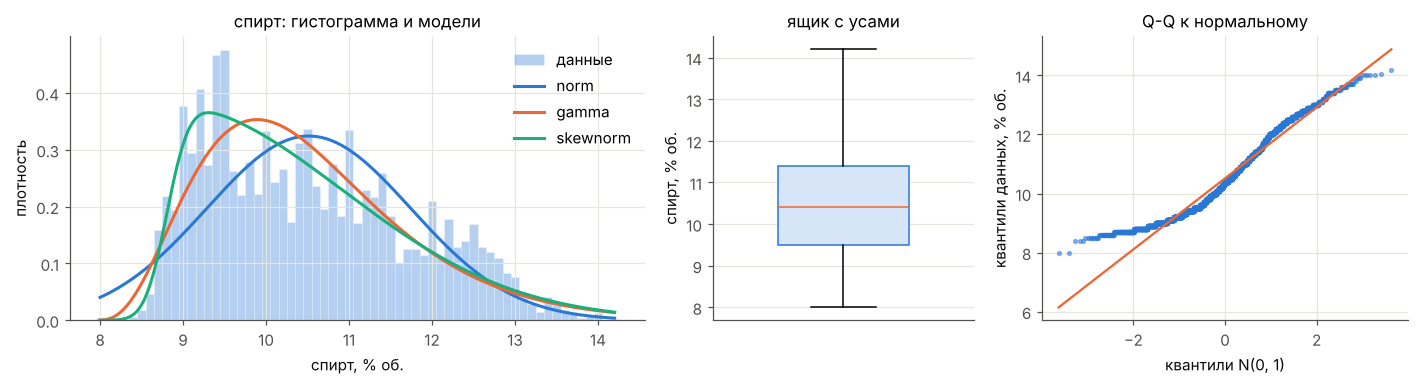

In [32]:
best_rv03 = {name: dist.fit(name, x_rv03) for name in ['norm', 'gamma', 'skewnorm']}
plots.eda_panel(x_rv03, "спирт", "% об.", best_rv03, "rv03_eda.png");

**Результаты:**

- Среднее 10.51, медиана 10.4, мода 9.4 % об., СКО 1.23, КВ 12 %, диапазон 8.0–14.2.
- Асимметрия +0.49, эксцесс −0.70. Выбросов по 1.5·IQR нет.
- Гистограмма с зубцами: на значения вида 9.0, 9.5, 10.0 … приходится 25 % вин; при равномерной последней цифре было бы 20 %. Интервалы гистограммы выровнены по шагу 0.1.
- AIC: скошенная нормальная 15125, гамма 15359, Вейбулл 15394, логнормальная 15450, нормальная 15936. D Колмогорова у всех ≥ 0.057.

<a id="rv03-math"></a>
#### Математическое описание распределения


**Проверяемое семейство: гамма-распределение со сдвигом** [2, 4] $\Gamma(k, \theta, \text{loc})$. Справочные формулы:

$$f(x) = \frac{(x-\text{loc})^{k-1}\,e^{-(x-\text{loc})/\theta}}{\Gamma(k)\,\theta^{k}},\quad x > \text{loc}.$$

- Моменты: $E X = \text{loc} + k\theta$, $D X = k\theta^2$, асимметрия $2/\sqrt{k}$, избыточный эксцесс $6/k$.
- При целом $k$ это сумма $k$ независимых показательных величин (распределение Эрланга); при $k\to\infty$ стремится к нормальному.
- Носитель: $x > \text{loc}$.

**TODO Сандра: обоснование выбора распределения своими словами.** _Вопросы: почему для проверки взято это семейство? что видно на гистограмме и Q-Q? что показали таблица AIC и H4? если ни одно семейство не подошло, что с этим делать в работе и для генератора во втором спринте?_

<a id="rv03-indep"></a>
### Independence & Estimations

**Зависимость.** Корреляции (Пирсон, Спирмен, Кендалл), хи-квадрат на таблице сопряжённости по квартилям и перестановочный тест.

In [33]:
print("спирт и pH")
display(dependence.correlations(white["alcohol"], white["ph"]))
chi = dependence.chi2_independence(white["alcohol"], white["ph"], bins=4)
perm = dependence.permutation_spearman(white["alcohol"], white["ph"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

спирт и pH


,coef,p
method,,
pearson,0.1214,1.4901e-17
spearman,0.1489,1.1419e-25
kendall,0.1026,5.8500e-26


χ² = 236.1, df = 9, p = 8.37e-46, V Крамера = 0.127
перестановочный тест: ρ = 0.149, p = 0.0005, |ρ| при H0 не больше 0.044


ph,0,1,2,3
alcohol,,,,
0,535,394,321,186
1,191,336,255,355
2,311,261,291,327
3,277,255,289,314


In [34]:
print("спирт и фиксированная кислотность")
display(dependence.correlations(white["alcohol"], white["fixed_acidity"]))
chi = dependence.chi2_independence(white["alcohol"], white["fixed_acidity"], bins=4)
perm = dependence.permutation_spearman(white["alcohol"], white["fixed_acidity"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

спирт и фиксированная кислотность


,coef,p
method,,
pearson,-0.1209,2.0854e-17
spearman,-0.1068,6.5824e-14
kendall,-0.0732,8.7284e-14


χ² = 94.6, df = 9, p = 1.98e-16, V Крамера = 0.080
перестановочный тест: ρ = -0.107, p = 0.0005, |ρ| при H0 не больше 0.051


fixed_acidity,0,1,2,3
alcohol,,,,
0,300,444,347,345
1,267,322,220,328
2,333,284,265,308
3,395,290,227,223


**Результаты:**

- **С pH:** ρ = +0.15, V Крамера 0.13. **С кислотностью:** ρ = −0.11, V Крамера 0.08. В обоих случаях p < 10⁻¹³, H0 о независимости отвергается.

**Состоятельность оценок.** Из совокупности берём выборки объёма n с возвращением (1000 повторов на каждое n) и смотрим, как оценка приближается к значению параметра в совокупности.

,оценка,n,theta,bias,sd_est,p_far,eps
0,mean,10,10.5143,2.7633e-03,0.3896,0.763,0.1230
1,mean,30,10.5143,-3.7214e-03,0.2245,0.590,0.1230
2,mean,100,10.5143,7.5319e-05,0.1197,0.298,0.1230
3,mean,300,10.5143,-1.8629e-03,0.0732,0.088,0.1230
4,mean,1000,10.5143,-2.0770e-03,0.0394,0.003,0.1230
5,mean,3000,10.5143,4.0594e-04,0.0220,0.000,0.1230
0,var,10,1.5141,3.1086e-03,0.5943,0.821,0.1514
1,var,30,1.5141,-8.8557e-03,0.3230,0.632,0.1514
2,var,100,1.5141,-2.5717e-03,0.1734,0.387,0.1514
3,var,300,1.5141,4.1169e-04,0.0988,0.116,0.1514


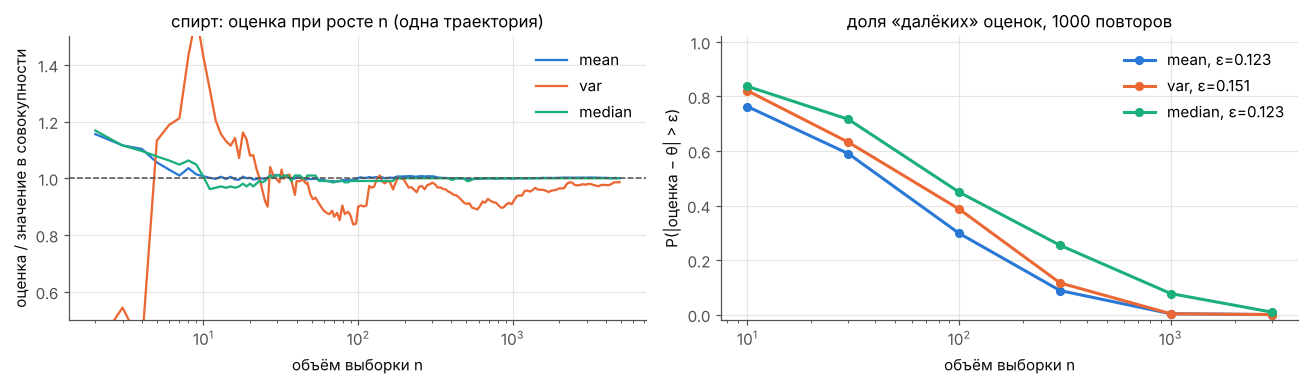

In [35]:
ns = [10, 30, 100, 300, 1000, 3000]
curves_rv03 = {e: estimation.consistency_curve(x_rv03, e, ns, reps=1000, seed=SEED) for e in ["mean", "var", "median"]}
running_rv03 = {e: estimation.running_estimate(x_rv03, e, n_max=4898, seed=SEED) for e in ["mean", "var", "median"]}
plots.consistency_panel(curves_rv03, running_rv03, "спирт", "rv03_consistency.png")
pd.concat(curves_rv03, names=["оценка"]).reset_index(level=0)[["оценка", "n", "theta", "bias", "sd_est", "p_far", "eps"]]

**Результаты:**

- ε = 0.123 % об. для среднего и медианы, 0.151 для дисперсии.
- При n = 10 → 3000: среднее 0.76 → 0.00, дисперсия 0.82 → 0.00, медиана 0.84 → 0.009.
- Смещение медианы от −0.03 до −0.06 при всех n; у среднего и дисперсии в пределах ±0.009.

<a id="rv03-norm"></a>
### Normalization

λ Бокса–Кокса = -1.481


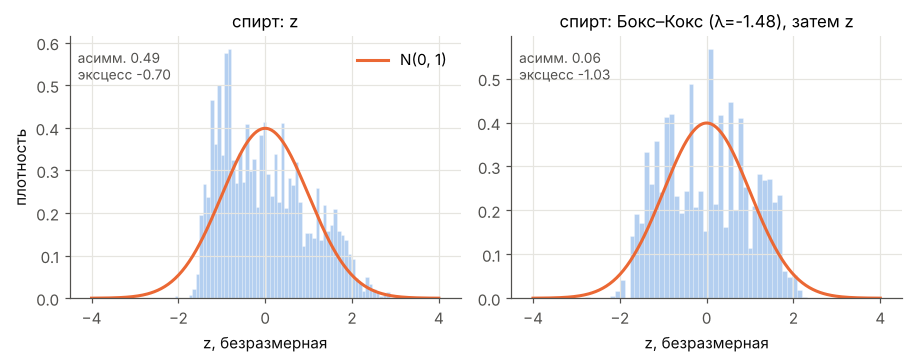

In [36]:
bc_alc, lam = normalize.boxcox(x_rv03)
print(f"λ Бокса–Кокса = {lam:.3f}")
plots.normalization_panel({"спирт: z": normalize.zscore(x_rv03), f"спирт: Бокс–Кокс (λ={lam:.2f}), затем z": normalize.zscore(bc_alc)},
                          "rv03_normalization.png");

**Результаты:**

- λ Бокса–Кокса = −1.48. После Бокса–Кокса и z: асимметрия 0.06, эксцесс −1.03 (до преобразования 0.49 и −0.70).

<a id="rv03-sample"></a>
### Sample vs Population

Одна выборка n = 300 (около 6 % совокупности) двумя способами, затем повторный эксперимент для разных n.

КС выборка против совокупности: с возвращением p = 0.400, без возвращения p = 0.733
Повторов элементов в выборке с возвращением: 11


,n,mean,std,median,q25,q75,skew,kurt,ДИ 95% для среднего
совокупность,4898.0,10.5143,1.2306,10.4,9.5,11.4,0.4872,-0.6989,
с возвращением,300.0,10.5948,1.2184,10.4,9.5,11.4,0.5083,-0.5369,"[10.4564, 10.7333]"
без возвращения,300.0,10.5990,1.2511,10.4,9.5,11.5,0.4422,-0.8922,"[10.4612, 10.7367]"


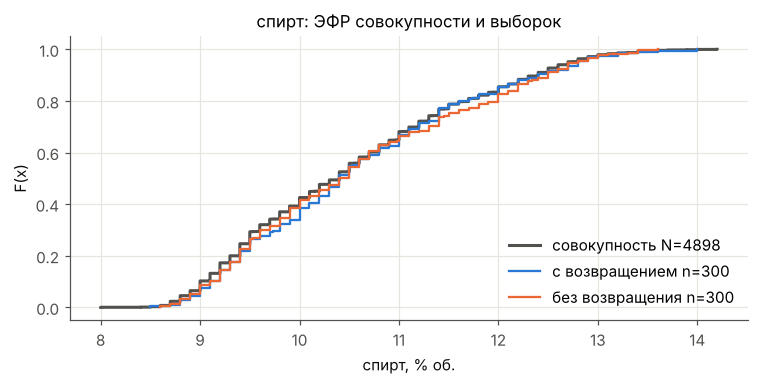

In [37]:
n = 300
s_with_rv03 = sampling.draw(x_rv03, n, replace=True, seed=SEED)
s_without_rv03 = sampling.draw(x_rv03, n, replace=False, seed=SEED)
tab = dsc.compare_table({"совокупность": x_rv03, "с возвращением": s_with_rv03, "без возвращения": s_without_rv03}).T
tab["ДИ 95% для среднего"] = ["", np.round(sampling.ci_mean(s_with_rv03), 4), np.round(sampling.ci_mean(s_without_rv03, N=len(x_rv03)), 4)]
ks_w, ks_wo = stats.ks_2samp(s_with_rv03, x_rv03), stats.ks_2samp(s_without_rv03, x_rv03)
print(f"КС выборка против совокупности: с возвращением p = {ks_w.pvalue:.3f}, без возвращения p = {ks_wo.pvalue:.3f}")
print("Повторов элементов в выборке с возвращением:", n - len(np.unique(sampling.draw(np.arange(len(x_rv03)), n, True, SEED))))
plots.sampling_panel(x_rv03, s_with_rv03, s_without_rv03, "спирт", "% об.", "rv03_sampling.png")
tab[["n", "mean", "std", "median", "q25", "q75", "skew", "kurt", "ДИ 95% для среднего"]]

,n,n/N,se_with_emp,se_with_theory,se_without_emp,se_without_theory
0,100,0.0204,0.1199,0.1230,0.1221,0.1218
1,1000,0.2042,0.0391,0.0389,0.0355,0.0347
2,2500,0.5104,0.0248,0.0246,0.0170,0.0172
3,4000,0.8167,0.0199,0.0195,0.0083,0.0083


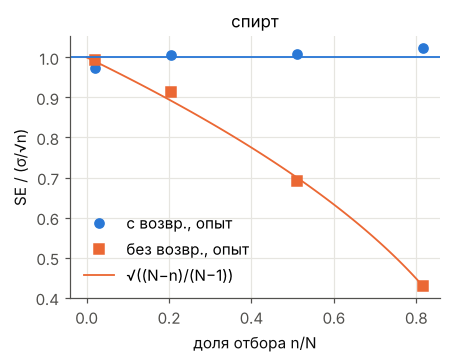

In [38]:
se_rv03 = sampling.se_mean_experiment(x_rv03, [100, 1000, 2500, 4000], reps=2000, seed=SEED)
plots.se_panel({"спирт": se_rv03}, "rv03_se.png")
se_rv03

**Результаты:**

- n = 300: среднее 10.59 и 10.60 при 10.51 в совокупности. 95 % ДИ [10.46; 10.73] и [10.46; 10.74], оба накрывают 10.51.
- КС p = 0.40 и 0.73. Квартили выборок отличаются от квартилей совокупности не больше чем на 0.1 % об.
- SE среднего без возвращения при n = 4000: 0.0083 против 0.0199; теория 0.0083.

<a id="rv03-hyp"></a>
### Hypotheses

Уровень значимости α = 0.05 для каждой проверки; поправка на множественность в [Lab resume](#resume).

,test,H0,p,decision
0,"χ² Пирсона, 19 интервалов, df 15",X ~ гамма со сдвигом,4.2792e-58,отвергаем H0
1,Mann–Whitney (greater),P(A > B) ≤ 1/2,2.2173e-140,отвергаем H0


Хороших вин 1060, остальных 3838; средний спирт 11.42 против 10.27 % об.
Оценка P(спирт у хорошего > спирт у остального) = 0.752


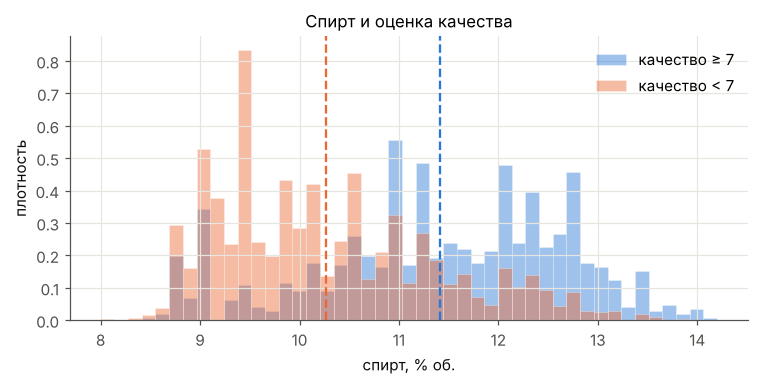

In [39]:
# H4: спирт распределён по гамма-закону со сдвигом
h4 = dist.chi2_gof(x_rv03, "gamma")
h4 |= {"test": f"χ² Пирсона, {h4['bins']} интервалов, df {h4['dof']}", "H0": "X ~ гамма со сдвигом"}
# H5: в хороших винах (качество ≥ 7) спирт не больше, чем в остальных: H0 P(A > B) ≤ 1/2
good, rest = white.alcohol[white.quality >= 7], white.alcohol[white.quality < 7]
h5 = hyp.mann_whitney(good, rest, alternative="greater")
h_rv03 = pd.DataFrame([h4, h5])[["test", "H0", "p", "decision"]]
display(h_rv03)
print(f"Хороших вин {len(good)}, остальных {len(rest)}; средний спирт {good.mean():.2f} против {rest.mean():.2f} % об.")
print(f"Оценка P(спирт у хорошего > спирт у остального) = {h5['p_a_gt_b']:.3f}")
plots.two_groups(good.to_numpy(), rest.to_numpy(), "качество ≥ 7", "качество < 7", "спирт, % об.",
                 "Спирт и оценка качества", "rv03_quality.png");

**Результаты:**

- **H4 (гамма со сдвигом):** χ² (19 интервалов, df 15) p ≈ 4·10⁻⁵⁸. H0 отвергается.
- **H5 (H0: P(спирт у вина с качеством ≥ 7 > у остального) ≤ 1/2):** Манн–Уитни p ≈ 10⁻¹⁴⁰, H0 отвергается. Средний спирт 11.42 против 10.27 % об.; оценка P(A > B) = 0.75.

<a id="rv03-resume"></a>
### Resume

**TODO Сандра: вывод своими словами.**

_Вопросы:_
- _Какой вывод о случайности спирта следует из R² и остатков обеих моделей?_
- _Связан ли спирт с pH и кислотностью? Чем статистическая значимость отличается от силы связи при N = 4898?_
- _Подошло ли какое-нибудь семейство? Что на гистограмме мешает (вершина, нижняя граница, зубцы)?_
- _Что значит оценка P(A > B) для хороших и остальных вин? Можно ли говорить о причине?_
- _Как могли повлиять значения спирта не на сетке 0.1 и «зубцы» гистограммы?_

<a id="resume"></a>
## Lab resume

### Итоговые метрики

In [40]:
summary = pd.DataFrame({
    "величина": ["pH", "фикс. кислотность", "спирт"],
    "единицы": ["ед. pH", "г/дм³", "% об."],
    "N": [len(x_rv01), len(x_rv02), len(x_rv03)],
    "среднее": [x.mean() for x in (x_rv01, x_rv02, x_rv03)],
    "СКО": [x.std(ddof=1) for x in (x_rv01, x_rv02, x_rv03)],
    "медиана": [np.median(x) for x in (x_rv01, x_rv02, x_rv03)],
    "асимметрия": [stats.skew(x) for x in (x_rv01, x_rv02, x_rv03)],
    "эксцесс": [stats.kurtosis(x) for x in (x_rv01, x_rv02, x_rv03)],
    "R² по 10 другим": [res_rv01["r2_cv"], res_rv02["r2_cv"], res_rv03["r2_cv"]],
    "проверяемое семейство": ["нормальное", "логнормальное", "гамма (сдвиг)"],
    "лучшая по AIC": [fit_rv01.index[0], fit_rv02.index[0], fit_rv03.index[0]],
}).set_index("величина")
summary

,единицы,N,среднее,СКО,медиана,асимметрия,эксцесс,R² по 10 другим,проверяемое семейство,лучшая по AIC
величина,,,,,,,,,,
pH,ед. pH,4898,3.1883,0.1510,3.18,0.4576,0.5290,0.5009,нормальное,skewnorm
фикс. кислотность,г/дм³,4898,6.8548,0.8439,6.80,0.6476,2.1687,0.5835,логнормальное,skewnorm
спирт,% об.,4898,10.5143,1.2306,10.40,0.4872,-0.6989,0.8609,гамма (сдвиг),skewnorm


### Все проверенные гипотезы и поправка Холма

In [41]:
all_h = pd.DataFrame([
    {"гипотеза": "H1 pH ~ нормальное (K², все 4898)", "p": h_rv01.p.iloc[0]},
    {"гипотеза": "H1b pH ~ логнормальное со сдвигом (χ²)", "p": chi_lognorm_rv01["p"]},
    {"гипотеза": "H2 E[pH белых] = E[pH красных]", "p": h2["p"]},
    {"гипотеза": "H3 ln(кислотности) ~ нормальное (K²)", "p": h_rv02.p.iloc[0]},
    {"гипотеза": "H3b кислотность ~ логнормальное со сдвигом (χ²)", "p": chi_ln3_rv02["p"]},
    {"гипотеза": "H4 спирт ~ гамма", "p": h4["p"]},
    {"гипотеза": "H5 спирт в хороших винах не выше", "p": h5["p"]},
    {"гипотеза": "H6 pH и кислотность независимы (χ²)", "p": dependence.chi2_independence(white.ph, white.fixed_acidity)["p"]},
    {"гипотеза": "H7 pH и спирт независимы (χ²)", "p": dependence.chi2_independence(white.ph, white.alcohol)["p"]},
    {"гипотеза": "H8 кислотность и спирт независимы (χ²)", "p": dependence.chi2_independence(white.fixed_acidity, white.alcohol)["p"]},
])
all_h["отвергаем (α=0.05, Холм)"] = hyp.holm(all_h.p)
all_h

,гипотеза,p,"отвергаем (α=0.05, Холм)"
0,"H1 pH ~ нормальное (K², все 4898)",1.0892e-42,True
1,H1b pH ~ логнормальное со сдвигом (χ²),5.5549e-02,False
2,H2 E[pH белых] = E[pH красных],2.3423e-149,True
3,H3 ln(кислотности) ~ нормальное (K²),1.8880e-21,True
4,H3b кислотность ~ логнормальное со сдвигом (χ²),3.0871e-06,True
5,H4 спирт ~ гамма,4.2792e-58,True
6,H5 спирт в хороших винах не выше,2.2173e-140,True
7,H6 pH и кислотность независимы (χ²),1.1055e-164,True
8,H7 pH и спирт независимы (χ²),8.3748e-46,True
9,H8 кислотность и спирт независимы (χ²),1.9800e-16,True


### Выводы по датасету

**TODO Сандра: общий вывод «как на лабах по физике», своими словами.** Преподаватель просит включить проверенные гипотезы и через них объяснить величины, а через величины сам датасет.

_Вопросы:_
- _что вы узнали о белых винах по трём величинам?_
- _какие H0 отвергнуты, какие нет (таблица выше)? почему при N = 4898 почти всё отвергается?_
- _какую величину вы возьмёте для датчика во втором спринте и почему?_
- _какие ограничения данных нашлись в EDA и как они могли повлиять на результаты?_
- _после выполнения можно сравнить с чужой аналитикой этого датасета и сослаться на неё._

### Литература и материалы

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. 2009. Vol. 47, № 4. P. 547–553. DOI 10.1016/j.dss.2009.05.016. Данные: UCI Machine Learning Repository, Wine Quality, DOI 10.24432/C56S3T.
2. Лагутин М. Б. Наглядная математическая статистика. М.: БИНОМ. Лаборатория знаний (рекомендовано преподавателем).
3. Кнут Д. Э. Искусство программирования. Т. 2. Получисленные алгоритмы. 3-е изд. М.: Вильямс (рекомендовано преподавателем, понадобится в спринте 2).
4. Leemis L. M., McQueston J. T. Univariate Distribution Relationships // The American Statistician. 2008. Vol. 62, № 1. P. 45–53 (файл 2008amstat.pdf из #useful_links курса).
5. Cochran W. G. Sampling Techniques. 3rd ed. New York: Wiley, 1977 (поправка на конечность совокупности).
6. D'Agostino R., Pearson E. S. Tests for departure from normality // Biometrika. 1973. Vol. 60, № 3. P. 613–622.
7. Wald A., Wolfowitz J. On a test whether two samples are from the same population // Annals of Mathematical Statistics. 1940. Vol. 11, № 2. P. 147–162 (критерий серий).
8. Waterhouse A. L., Sacks G. L., Jeffery D. W. Understanding Wine Chemistry. Wiley, 2016 (химия кислот и pH вина).
9. Chernoff H., Lehmann E. L. The use of maximum likelihood estimates in χ² tests for goodness of fit // Annals of Mathematical Statistics. 1954. Vol. 25, № 3. P. 579–586 (почему параметры для χ² оцениваются по интервалам).
10. Lilliefors H. W. On the Kolmogorov–Smirnov test for normality with mean and variance unknown // Journal of the American Statistical Association. 1967. Vol. 62, № 318. P. 399–402 (КС с оценёнными параметрами).

**TODO Сандра:** найти и добавить источники из библиотек (РГБ, РНБ, ИТМО, eLibrary, IEEE, ResearchGate): за подбор литературы отдельный балл.

### cat_mark_table

Критерии, которые, по нашему мнению, закрыты в спринте 1 (коэффициент выставляет преподаватель).

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| lab.ic.01.01 | [RV01](#rv01), [RV02](#rv02), [RV03](#rv03) | | три величины, для каждой доказана стохастическая природа |
| lab.ic.01.02 | [RV01 зависимость](#rv01-indep), [RV02](#rv02-indep), [RV03](#rv03-indep) | | pH и кислотность (одна природа): зависимы; спирт с ними слабо зависим |
| lab.ic.01.03 | [RV01](#rv01-indep), [RV02](#rv02-indep), [RV03](#rv03-indep) | | состоятельность среднего, дисперсии, медианы: P(отклонение > ε) → 0 |
| lab.ic.01.04 | [датасет](#dataset), [RV01](#rv01-eda), [RV02](#rv02-eda), [RV03](#rv03-eda) | | пропуски, дубли, округление, выбросы, сравнение с красными |
| lab.ic.01.05 | [RV01](#rv01-norm), [RV02](#rv02-norm), [RV03](#rv03-norm) | | стандартизация z, min-max, ln, Бокс–Кокс |
| lab.ic.01.06 | [RV01](#rv01-math), [RV02](#rv02-math), [RV03](#rv03-math) | | проверены разные семейства: нормальное, логнормальное, гамма. **TODO Сандра: решить, заявлять ли** (по AIC у всех трёх лучше skewnorm) |
| lab.ic.01.07 | [RV01 мат. описание](#rv01-math) | | нормальное распределение; **TODO Сандра: обоснование** |
| lab.ic.01.08 | [RV02](#rv02-math), [RV03](#rv03-math) | | логнормальное и гамма; **TODO Сандра: обоснование** |
| lab.ic.01.09 | [RV01](#rv01-sample), [RV02](#rv02-sample), [RV03](#rv03-sample) | | выборки с возвращением и без |
| lab.ic.01.10 | там же + Resume каждой величины | | **TODO Сандра: выводы** |
| lab.ic.01.11 | [RV01 гипотезы](#rv01-hyp) | | H1 нормальность pH |
| lab.ic.01.12 | [RV01](#rv01-hyp), [RV02](#rv02-hyp), [RV03](#rv03-hyp), [сводка](#resume) | | H1b, H2, H3, H3b, H4–H8 |
| lab.ic.01.19 | [литература](#resume) | | ссылки на материалы |
| lab.ic.01.21 | [литература](#resume) | | **TODO Сандра: дополнить из библиотек** |
| lab.ic.01.24 | [итоговые метрики](#resume) | | таблицы метрик и гипотез |

# Lab01 - sprint 2

Раздел появится во втором спринте: датчик случайных чисел на основе одной из величин.

```
## random 01
### Description
### math desc
### code
### tests
### resume
## Lab resume
### cat_mark_table
```